A single decision tree memorises its training set. Flip one label and the very first
question can change &mdash; the tree has **low bias but high variance**.

A random forest fixes that with one idea:

> Grow many trees, each on a slightly different view of the data,
> then average them.

Averaging is what kills variance. But it only works if the trees **disagree**, so a
forest injects randomness twice: each tree sees a *bootstrap resample* of the rows, and
each split may only consider a *random subset of the features*.

The chain is:

**bootstrap the rows &rarr; subsample the features &rarr; grow a tree &rarr; repeat &rarr; average the votes**

Every one of those steps is shown below with the actual indices drawn and the actual
votes counted, and the variance-reduction claim is checked numerically at the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from library: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 12 EEG recordings used in the Decision Tree walkthrough, so the two can be
compared directly.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
# --- the tree machinery from the Decision Tree notebook, in compact form ---
def gini(y):
    if len(y) == 0:
        return 0.0
    _, c = np.unique(y, return_counts=True)
    p = c / c.sum()
    return float(1.0 - np.sum(p ** 2))


def candidate_thresholds(col):
    v = np.unique(col)
    return (v[:-1] + v[1:]) / 2.0


def split_score(Xs, ys, f, t):
    L = Xs[:, f] <= t
    if L.all() or (~L).all():
        return -1.0
    return gini(ys) - (L.mean() * gini(ys[L]) + (~L).mean() * gini(ys[~L]))


def best_split(Xs, ys, feats):
    best = (-1.0, None, None)
    for f in feats:
        for t in candidate_thresholds(Xs[:, f]):
            g = split_score(Xs, ys, f, t)
            if g > best[0]:
                best = (g, f, float(t))
    return best


class Node:
    __slots__ = ("feature", "threshold", "left", "right", "pred", "n", "gain", "idx")
    def __init__(self):
        self.feature = self.threshold = self.left = self.right = None
        self.pred = self.n = self.gain = self.idx = None


def grow(idx, Xa, ya, max_depth, max_features, rng, depth=0):
    nd = Node()
    nd.idx, nd.n = idx, len(idx)
    y = ya[idx]
    nd.pred = int(np.argmax(np.bincount(y, minlength=2)))
    if depth >= max_depth or gini(y) == 0.0 or len(idx) < 2:
        return nd
    feats = rng.choice(Xa.shape[1], size=max_features, replace=False)
    g, f, t = best_split(Xa[idx], y, sorted(feats))
    if f is None or g <= 0:
        return nd
    nd.feature, nd.threshold, nd.gain = f, t, g
    m = Xa[idx, f] <= t
    nd.left  = grow(idx[m],  Xa, ya, max_depth, max_features, rng, depth + 1)
    nd.right = grow(idx[~m], Xa, ya, max_depth, max_features, rng, depth + 1)
    return nd


def tree_predict(nd, x):
    while nd.feature is not None:
        nd = nd.left if x[nd.feature] <= nd.threshold else nd.right
    return nd.pred


def show_tree(nd, ya, prefix="", branch=""):
    if nd.feature is None:
        c = np.bincount(ya[nd.idx], minlength=2)
        print(f"{prefix}{branch}LEAF predict {nd.pred}  n={nd.n} [{c[0]} neg, {c[1]} pos]")
        return
    print(f"{prefix}{branch}[{feature_names[nd.feature]} <= {nd.threshold:.2f}] n={nd.n}")
    pad = prefix + ("    " if branch else "")
    show_tree(nd.left, ya, pad, "|-- yes: ")
    show_tree(nd.right, ya, pad, "|-- no : ")


print("Tree machinery ready: gini, best_split, grow, tree_predict, show_tree.")

Tree machinery ready: gini, best_split, grow, tree_predict, show_tree.


---
# 2. The Bootstrap

Each tree is trained on $n$ rows drawn **with replacement** from the original $n$. Some
rows arrive two or three times; others are never drawn at all.

The probability that a particular row is missed by one draw is $1 - \frac{1}{n}$, so
after $n$ independent draws:

$$P(\text{row never drawn}) = \left(1 - \frac{1}{n}\right)^{n}
\;\xrightarrow[n \to \infty]{}\; e^{-1} \approx 0.368$$

So roughly **37% of the rows are left out of every tree**. Those are the
**out-of-bag (OOB)** samples, and they are free validation data.

In [4]:
n = n_samples
p_miss_one = 1 - 1/n
p_miss_all = p_miss_one ** n

print(f"n = {n} rows\n")
print(f"P(a given row is missed by ONE draw)   = 1 - 1/{n} = {p_miss_one:.6f}")
print(f"P(missed by all {n} draws)              = ({p_miss_one:.6f})^{n} = {p_miss_all:.6f}")
print(f"limit as n -> infinity                 = e^-1 = {np.exp(-1):.6f}")
print(f"\nso about {p_miss_all*100:.1f}% of rows are out-of-bag for each tree,")
print(f"and about {(1-p_miss_all)*100:.1f}% are in-bag.\n")

rng_demo = np.random.default_rng(0)
trials = 20000
oob_frac = np.mean([len(np.unique(rng_demo.integers(0, n, n))) for _ in range(trials)])
print(f"empirical check over {trials} simulated bootstraps:")
print(f"   mean distinct rows in-bag = {oob_frac:.4f} of {n}  "
      f"-> in-bag fraction {oob_frac/n:.6f}")
print(f"   predicted in-bag fraction = {1 - p_miss_all:.6f}")
print(f"   MATCH: {np.isclose(oob_frac/n, 1 - p_miss_all, atol=5e-3)}")

n = 12 rows

P(a given row is missed by ONE draw)   = 1 - 1/12 = 0.916667
P(missed by all 12 draws)              = (0.916667)^12 = 0.351996
limit as n -> infinity                 = e^-1 = 0.367879

so about 35.2% of rows are out-of-bag for each tree,
and about 64.8% are in-bag.

empirical check over 20000 simulated bootstraps:
   mean distinct rows in-bag = 7.7764 of 12  -> in-bag fraction 0.648033
   predicted in-bag fraction = 0.648004
   MATCH: True


### The actual draws

Below are the bootstrap samples for the five trees this forest will use. Read the
*count* row as "how many copies of this recording this tree sees" &mdash; a zero means the
recording is out-of-bag for that tree.

In [5]:
B = 5
MAX_DEPTH = 2
MAX_FEATURES = 2
rng = np.random.default_rng(7)

boot_idx, oob_idx = [], []
for b in range(B):
    idx = rng.integers(0, n, n)
    boot_idx.append(idx)
    oob_idx.append(np.setdiff1d(np.arange(n), np.unique(idx)))

hdr = f"{'tree':>5}  " + "  ".join(f"{r[3:]:>3}" for r in rec_ids) + f"  {'#OOB':>5}"
print("counts of each recording in each bootstrap sample\n")
print(hdr); print("-" * len(hdr))
for b in range(B):
    cnt = np.bincount(boot_idx[b], minlength=n)
    print(f"{b:>5}  " + "  ".join(f"{c:>3}" for c in cnt) + f"  {len(oob_idx[b]):>5}")
print("-" * len(hdr))

print(f"\nmean OOB size = {np.mean([len(o) for o in oob_idx]):.2f} of {n} "
      f"= {np.mean([len(o) for o in oob_idx])/n:.3f}  (theory {p_miss_all:.3f})")
for b in range(B):
    print(f"   tree {b}: in-bag rows {sorted(set(boot_idx[b].tolist()))}")
    print(f"           OOB rows    {oob_idx[b].tolist()}")

counts of each recording in each bootstrap sample

 tree   00   01   02   03   04   05   06   07   08   09   10   11   #OOB
------------------------------------------------------------------------
    0    1    0    1    2    0    0    1    1    1    1    3    1      3
    1    1    2    0    2    1    2    0    0    0    3    1    0      5
    2    0    0    0    1    0    2    4    0    1    2    0    2      6
    3    1    2    1    0    1    1    0    2    1    0    2    1      3
    4    1    1    0    0    0    3    2    1    0    2    0    2      5
------------------------------------------------------------------------

mean OOB size = 4.40 of 12 = 0.367  (theory 0.352)
   tree 0: in-bag rows [0, 2, 3, 6, 7, 8, 9, 10, 11]
           OOB rows    [1, 4, 5]
   tree 1: in-bag rows [0, 1, 3, 4, 5, 9, 10]
           OOB rows    [2, 6, 7, 8, 11]
   tree 2: in-bag rows [3, 5, 6, 8, 9, 11]
           OOB rows    [0, 1, 2, 4, 7, 10]
   tree 3: in-bag rows [0, 1, 2, 4, 5, 7, 8, 10, 11]
  

---
# 3. Feature Subsampling

Bootstrapping alone is not enough. If one feature dominates &mdash; as `spike_rate` does
here &mdash; every tree picks it at the root and the trees end up nearly identical.
Averaging near-identical trees reduces nothing.

So at **every split**, only a random subset of $m$ features is considered:

$$m = \texttt{max\_features}, \qquad \text{commonly } m = \lfloor\sqrt{p}\rfloor \text{ for classification}$$

This deliberately handicaps each tree so that the forest as a whole is more diverse.

In [6]:
print(f"p = {n_features} features, using max_features = {MAX_FEATURES} per split\n")
from math import comb
print(f"number of possible feature subsets of size {MAX_FEATURES}: "
      f"{comb(n_features, MAX_FEATURES)}\n")

rng_f = np.random.default_rng(7)
print("Which features each tree's ROOT split was allowed to consider:")
forest = []
for b in range(B):
    tr = grow(boot_idx[b], X, y_class, MAX_DEPTH, MAX_FEATURES, rng_f)
    forest.append(tr)

for b, tr in enumerate(forest):
    chosen = feature_names[tr.feature] if tr.feature is not None else "(none)"
    print(f"   tree {b}: root question -> {chosen}"
          + (f" <= {tr.threshold:.2f}" if tr.feature is not None else ""))

roots = [t.feature for t in forest if t.feature is not None]
print(f"\ndistinct root features across the forest: "
      f"{sorted(set(feature_names[f] for f in roots))}")
print("Without feature subsampling every one of these would be spike_rate.")

p = 3 features, using max_features = 2 per split

number of possible feature subsets of size 2: 3

Which features each tree's ROOT split was allowed to consider:
   tree 0: root question -> spike_rate <= 3.55
   tree 1: root question -> spike_rate <= 3.75
   tree 2: root question -> line_length <= 24.50
   tree 3: root question -> spike_rate <= 3.55
   tree 4: root question -> line_length <= 25.00

distinct root features across the forest: ['line_length', 'spike_rate']
Without feature subsampling every one of these would be spike_rate.


### The five trees

Each is shallow (`max_depth = 2`) and each was grown on different rows with different
features available. They are *supposed* to be individually mediocre.

In [7]:
for b, tr in enumerate(forest):
    ib = sorted(set(boot_idx[b].tolist()))
    print(f"===== TREE {b} =====  in-bag rows {ib}")
    show_tree(tr, y_class)
    p = np.array([tree_predict(tr, X[i]) for i in range(n)])
    acc_all = (p == y_class).mean()
    o = oob_idx[b]
    acc_oob = (p[o] == y_class[o]).mean() if len(o) else float("nan")
    print(f"   accuracy on all 12 rows: {acc_all:.4f}   |   on its {len(o)} OOB rows: {acc_oob:.4f}")
    print()

===== TREE 0 =====  in-bag rows [0, 2, 3, 6, 7, 8, 9, 10, 11]
[spike_rate <= 3.55] n=12
|-- yes: [spike_rate <= 2.15] n=6
    |-- yes: LEAF predict 0  n=3 [2 neg, 1 pos]
    |-- no : LEAF predict 0  n=3 [3 neg, 0 pos]
|-- no : LEAF predict 1  n=6 [0 neg, 6 pos]
   accuracy on all 12 rows: 0.9167   |   on its 3 OOB rows: 1.0000

===== TREE 1 =====  in-bag rows [0, 1, 3, 4, 5, 9, 10]
[spike_rate <= 3.75] n=12
|-- yes: LEAF predict 0  n=5 [5 neg, 0 pos]
|-- no : LEAF predict 1  n=7 [0 neg, 7 pos]
   accuracy on all 12 rows: 0.9167   |   on its 5 OOB rows: 0.8000

===== TREE 2 =====  in-bag rows [3, 5, 6, 8, 9, 11]
[line_length <= 24.50] n=12
|-- yes: LEAF predict 0  n=1 [1 neg, 0 pos]
|-- no : LEAF predict 1  n=11 [0 neg, 11 pos]
   accuracy on all 12 rows: 0.9167   |   on its 6 OOB rows: 0.8333

===== TREE 3 =====  in-bag rows [0, 1, 2, 4, 5, 7, 8, 10, 11]
[spike_rate <= 3.55] n=12
|-- yes: LEAF predict 0  n=7 [7 neg, 0 pos]
|-- no : LEAF predict 1  n=5 [0 neg, 5 pos]
   accuracy on all 

---
# 4. Voting

For classification the forest averages the trees' class probabilities and takes the
larger one. With hard 0/1 votes from each tree this reduces to a majority:

$$\hat{p}_1(x) = \frac{1}{B}\sum_{b=1}^{B} \mathbb{1}[T_b(x) = 1],
\qquad
\hat{y}(x) = \mathbb{1}\!\left[\hat{p}_1(x) > 0.5\right]$$

The table below is the whole prediction step: one column per tree, one row per
recording.

In [8]:
votes = np.array([[tree_predict(tr, X[i]) for tr in forest] for i in range(n)])
p1 = votes.mean(axis=1)
forest_pred = (p1 > 0.5).astype(int)

hdr = (f"{'id':>6}  " + "  ".join(f"{'T'+str(b):>3}" for b in range(B)) +
       f"  {'votes for 1':>12}  {'p1':>7}  {'pred':>5}  {'true':>5}  {'ok':>4}")
print(hdr); print("-" * len(hdr))
for i in range(n):
    ok = "yes" if forest_pred[i] == y_class[i] else "NO"
    print(f"{rec_ids[i]:>6}  " + "  ".join(f"{v:>3}" for v in votes[i]) +
          f"  {int(votes[i].sum()):>6}/{B:<5}  {p1[i]:>7.3f}  "
          f"{forest_pred[i]:>5}  {y_class[i]:>5}  {ok:>4}")
print("-" * len(hdr))

print(f"\nworked example, {rec_ids[0]}:")
print(f"   tree votes = {votes[0].tolist()}")
print(f"   p1 = ({' + '.join(str(v) for v in votes[0])}) / {B} = "
      f"{votes[0].sum()}/{B} = {p1[0]:.4f}")
print(f"   {p1[0]:.4f} > 0.5 ? {'yes -> predict 1' if p1[0] > .5 else 'no  -> predict 0'}")

print(f"\nforest accuracy       : {(forest_pred == y_class).mean():.4f}")
single = np.array([tree_predict(forest[0], X[i]) for i in range(n)])
print(f"best single tree accuracy: "
      f"{max((np.array([tree_predict(t, X[i]) for i in range(n)]) == y_class).mean() for t in forest):.4f}")
print(f"mean single tree accuracy: "
      f"{np.mean([(np.array([tree_predict(t, X[i]) for i in range(n)]) == y_class).mean() for t in forest]):.4f}")

    id   T0   T1   T2   T3   T4   votes for 1       p1   pred   true    ok
--------------------------------------------------------------------------
 rec00    0    0    0    0    0       0/5        0.000      0      0   yes
 rec01    0    0    0    0    0       0/5        0.000      0      0   yes
 rec02    1    1    1    1    1       5/5        1.000      1      1   yes
 rec03    1    1    1    1    1       5/5        1.000      1      1   yes
 rec04    0    0    0    0    0       0/5        0.000      0      0   yes
 rec05    1    1    1    1    1       5/5        1.000      1      1   yes
 rec06    0    0    1    0    1       2/5        0.400      0      1    NO
 rec07    1    1    1    1    1       5/5        1.000      1      1   yes
 rec08    0    0    0    0    0       0/5        0.000      0      0   yes
 rec09    1    1    1    1    1       5/5        1.000      1      1   yes
 rec10    0    0    1    0    1       2/5        0.400      0      0   yes
 rec11    1    1    1    

---
# 5. Out-of-Bag Error

Every tree left roughly a third of the rows unseen. Predicting row $i$ using **only the
trees for which $i$ was out-of-bag** gives an honest estimate of generalisation error
without holding out a separate validation set:

$$\hat{y}^{\text{oob}}_i = \text{majority}\{\, T_b(x_i) \;:\; i \notin \text{bag}(b) \,\}$$

This is the practical reason bagging is attractive on small datasets: the validation
set comes free.

In [9]:
print(f"{'id':>6}  {'trees where OOB':>22}  {'their votes':>14}  {'oob pred':>9}  {'true':>5}  {'ok':>4}")
print("-" * 74)
oob_pred = np.full(n, -1)
for i in range(n):
    which = [b for b in range(B) if i in set(oob_idx[b].tolist())]
    if not which:
        print(f"{rec_ids[i]:>6}  {'(none - in every bag)':>22}")
        continue
    vs = [int(tree_predict(forest[b], X[i])) for b in which]
    oob_pred[i] = int(np.mean(vs) > 0.5)
    ok = "yes" if oob_pred[i] == y_class[i] else "NO"
    print(f"{rec_ids[i]:>6}  {str(which):>22}  {str(vs):>14}  "
          f"{oob_pred[i]:>9}  {y_class[i]:>5}  {ok:>4}")
print("-" * 74)

have = oob_pred >= 0
oob_acc = (oob_pred[have] == y_class[have]).mean()
print(f"\nrows with at least one OOB tree: {have.sum()} of {n}")
print(f"OOB accuracy = {(oob_pred[have] == y_class[have]).sum()}/{have.sum()} = {oob_acc:.4f}")
print(f"OOB error    = {1 - oob_acc:.4f}")
print(f"\n(training accuracy was {(forest_pred == y_class).mean():.4f} - the OOB number is")
print(f" the honest one, because no tree used those rows to choose its splits.)")

    id         trees where OOB     their votes   oob pred   true    ok
--------------------------------------------------------------------------
 rec00                     [2]             [0]          0      0   yes
 rec01                  [0, 2]          [0, 0]          0      0   yes
 rec02               [1, 2, 4]       [1, 1, 1]          1      1   yes
 rec03                  [3, 4]          [1, 1]          1      1   yes
 rec04               [0, 2, 4]       [0, 0, 0]          0      0   yes
 rec05                     [0]             [1]          1      1   yes
 rec06                  [1, 3]          [0, 0]          0      1    NO
 rec07                  [1, 2]          [1, 1]          1      1   yes
 rec08                  [1, 4]          [0, 0]          0      0   yes
 rec09                     [3]             [1]          1      1   yes
 rec10                  [2, 4]          [1, 1]          1      0    NO
 rec11                     [1]             [1]          1      1   yes
--

---
# 6. Why Averaging Works

Suppose each tree has prediction variance $\sigma^2$ and any two trees are correlated
by $\rho$. The variance of their average is:

$$\operatorname{Var}\!\left(\frac{1}{B}\sum_b T_b\right)
= \rho\,\sigma^2 \;+\; \frac{1-\rho}{B}\,\sigma^2$$

Two things follow, and they explain the entire design of a random forest:

1. The second term vanishes as $B \to \infty$ &mdash; **more trees never hurt**.
2. The first term does **not** vanish. The floor is $\rho\sigma^2$, so the only way to
   improve further is to make the trees **less correlated**. That is exactly what
   `max_features` buys, at the cost of a slightly worse individual tree.

variance of the averaged prediction, by correlation between trees

    B  rho=0.00   rho=0.30   rho=0.60   rho=0.90 
----------------------------------------------
    1  1.0000     1.0000     1.0000     1.0000   
    2  0.5000     0.6500     0.8000     0.9500   
    5  0.2000     0.4400     0.6800     0.9200   
   10  0.1000     0.3700     0.6400     0.9100   
   25  0.0400     0.3280     0.6160     0.9040   
   50  0.0200     0.3140     0.6080     0.9020   
  100  0.0100     0.3070     0.6040     0.9010   
  200  0.0050     0.3035     0.6020     0.9005   
----------------------------------------------

read the last row: with 200 trees the variance has essentially reached its
floor of rho * sigma^2. At rho = 0.9 that floor is 0.9 - almost no gain from
averaging, because the trees all say the same thing.



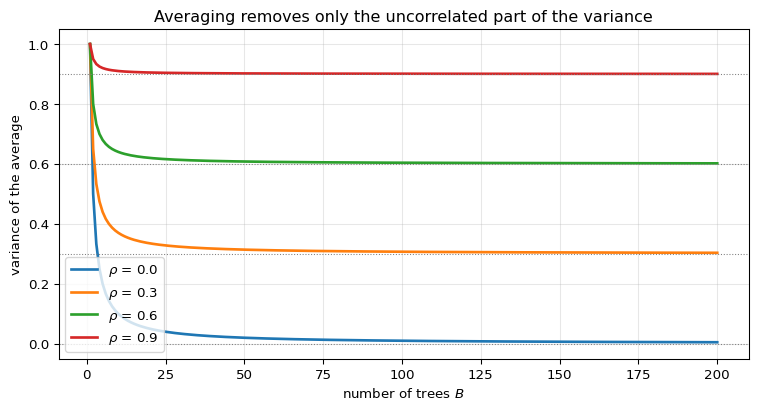

rho = 0.0, B = 20 -> simulated var 0.0501, formula 0.0500, MATCH: True
rho = 0.5, B = 20 -> simulated var 0.5254, formula 0.5250, MATCH: True
rho = 0.9, B = 20 -> simulated var 0.9058, formula 0.9050, MATCH: True


In [10]:
rng_v = np.random.default_rng(1)
sigma2, B_grid = 1.0, np.arange(1, 201)

print("variance of the averaged prediction, by correlation between trees\n")
print(f"{'B':>5}  " + "  ".join(f"rho={r:<5.2f}" for r in (0.0, 0.3, 0.6, 0.9)))
print("-" * 46)
for Bv in (1, 2, 5, 10, 25, 50, 100, 200):
    row = [rho * sigma2 + (1 - rho) / Bv * sigma2 for rho in (0.0, 0.3, 0.6, 0.9)]
    print(f"{Bv:>5}  " + "  ".join(f"{v:<9.4f}" for v in row))
print("-" * 46)
print("\nread the last row: with 200 trees the variance has essentially reached its")
print("floor of rho * sigma^2. At rho = 0.9 that floor is 0.9 - almost no gain from")
print("averaging, because the trees all say the same thing.\n")

plt.figure(figsize=(8, 4.4))
for rho in (0.0, 0.3, 0.6, 0.9):
    plt.plot(B_grid, rho + (1 - rho) / B_grid, lw=2, label=f"$\\rho$ = {rho}")
    plt.axhline(rho, color="grey", ls=":", lw=.8)
plt.xlabel("number of trees $B$"); plt.ylabel("variance of the average")
plt.title("Averaging removes only the uncorrelated part of the variance")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

emp = []
for rho_t in (0.0, 0.5, 0.9):
    z = rng_v.normal(size=(20000, 1))
    e = rng_v.normal(size=(20000, 20))
    trees = np.sqrt(rho_t) * z + np.sqrt(1 - rho_t) * e     # corr(T_i, T_j) = rho_t
    v = trees.mean(axis=1).var()
    pred = rho_t + (1 - rho_t) / 20
    print(f"rho = {rho_t:.1f}, B = 20 -> simulated var {v:.4f}, formula {pred:.4f}, "
          f"MATCH: {np.isclose(v, pred, atol=0.02)}")

---
# 7. Feature Importance

The standard forest importance is **mean decrease in impurity (MDI)**: every split that
uses a feature contributes the impurity it removed, weighted by how many samples passed
through that node.

$$\text{Imp}(f) = \frac{1}{B}\sum_{b}\; \sum_{\substack{\text{nodes } v \in T_b \\ \text{split on } f}}
\frac{n_v}{n}\,\Big(G_v - \tfrac{n_L}{n_v}G_L - \tfrac{n_R}{n_v}G_R\Big)$$

Below the formula is applied by hand to a fitted scikit-learn tree and compared with
its own `feature_importances_`, which is the cleanest possible check that the formula
is the one the library actually uses.

In [11]:
from sklearn.tree import DecisionTreeClassifier

sk_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=0).fit(X, y_class)
tt = sk_tree.tree_

print("walking scikit-learn's own tree structure\n")
print(f"{'node':>5}  {'feature':>12}  {'n_v':>4}  {'G_v':>8}  {'nL':>3}  {'G_L':>8}  "
      f"{'nR':>3}  {'G_R':>8}  {'weighted drop':>14}")
print("-" * 84)
manual_imp = np.zeros(n_features)
for v in range(tt.node_count):
    l, r = tt.children_left[v], tt.children_right[v]
    if l == -1:
        continue
    nv, nl, nr = tt.weighted_n_node_samples[v], tt.weighted_n_node_samples[l], tt.weighted_n_node_samples[r]
    Gv, Gl, Gr = tt.impurity[v], tt.impurity[l], tt.impurity[r]
    drop = (nv / n) * (Gv - (nl / nv) * Gl - (nr / nv) * Gr)
    manual_imp[tt.feature[v]] += drop
    print(f"{v:>5}  {feature_names[tt.feature[v]]:>12}  {int(nv):>4}  {Gv:>8.5f}  "
          f"{int(nl):>3}  {Gl:>8.5f}  {int(nr):>3}  {Gr:>8.5f}  {drop:>14.6f}")
print("-" * 84)

print(f"\nunnormalised totals : {np.round(manual_imp, 6)}")
manual_norm = manual_imp / manual_imp.sum()
print(f"normalised (sum = 1): {np.round(manual_norm, 6)}")
print(f"sklearn              : {np.round(sk_tree.feature_importances_, 6)}")
print(f"\nMATCH: {np.allclose(manual_norm, sk_tree.feature_importances_)}")

print(f"\n{'feature':>12}  {'importance':>11}")
print("-" * 26)
for f in np.argsort(-manual_norm):
    bar = "#" * int(round(manual_norm[f] * 40))
    print(f"{feature_names[f]:>12}  {manual_norm[f]:>11.4f}  {bar}")

walking scikit-learn's own tree structure

 node       feature   n_v       G_v   nL       G_L   nR       G_R   weighted drop
------------------------------------------------------------------------------------
    0    spike_rate    12   0.48611    6   0.27778    6   0.00000        0.347222
    1           age     6   0.27778    4   0.00000    2   0.50000        0.055556
    3   line_length     2   0.50000    1   0.00000    1   0.00000        0.083333
------------------------------------------------------------------------------------

unnormalised totals : [0.0833 0.3472 0.0556]
normalised (sum = 1): [0.1714 0.7143 0.1143]
sklearn              : [0.1714 0.7143 0.1143]

MATCH: True

     feature   importance
--------------------------
  spike_rate       0.7143  #############################
 line_length       0.1714  #######
         age       0.1143  #####


### The known bias of MDI

MDI is cheap but it flatters high-cardinality features: a continuous column offers many
more thresholds to try, so it wins splits partly by luck. Permutation importance, which
measures the accuracy lost when a column is shuffled, does not have that bias.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

rf = RandomForestClassifier(n_estimators=300, max_depth=3, max_features=2,
                            oob_score=True, bootstrap=True, random_state=0).fit(X, y_class)

perm = permutation_importance(rf, X, y_class, n_repeats=50, random_state=0)

print(f"{'feature':>12}  {'MDI (forest)':>13}  {'permutation':>12}")
print("-" * 42)
for f in range(n_features):
    print(f"{feature_names[f]:>12}  {rf.feature_importances_[f]:>13.4f}  "
          f"{perm.importances_mean[f]:>12.4f}")
print("-" * 42)
print("\nBoth agree that spike_rate carries most of the signal, which matches the")
print("single-split analysis from the Decision Tree walkthrough.")

     feature   MDI (forest)   permutation
------------------------------------------
 line_length         0.2748        0.0250
  spike_rate         0.5401        0.4283
         age         0.1851        0.0000
------------------------------------------

Both agree that spike_rate carries most of the signal, which matches the
single-split analysis from the Decision Tree walkthrough.


---
# 8. Checking Against scikit-learn

Two claims are checked here.

**A forest really is just an average.** Averaging the `predict_proba` of every
individual estimator inside a fitted `RandomForestClassifier` must reproduce the
forest's own `predict_proba` exactly.

**The OOB score is what it says it is.** `oob_score_` should equal the accuracy of
out-of-bag voting.

In [13]:
manual_proba = np.mean([est.predict_proba(X) for est in rf.estimators_], axis=0)
rf_proba = rf.predict_proba(X)

print(f"{'id':>6}  {'manual avg P(1)':>16}  {'rf.predict_proba':>17}  {'diff':>10}")
print("-" * 56)
for i in range(n):
    print(f"{rec_ids[i]:>6}  {manual_proba[i,1]:>16.8f}  {rf_proba[i,1]:>17.8f}  "
          f"{abs(manual_proba[i,1]-rf_proba[i,1]):>10.2e}")
print("-" * 56)
print(f"\naveraging {len(rf.estimators_)} trees by hand == rf.predict_proba   "
      f"MATCH: {np.allclose(manual_proba, rf_proba)}")
print(f"argmax of the average == rf.predict                MATCH: "
      f"{np.array_equal(manual_proba.argmax(1), rf.predict(X))}")

print(f"\nforest training accuracy : {rf.score(X, y_class):.4f}")
print(f"forest OOB score         : {rf.oob_score_:.4f}")
print(f"our 5-tree OOB accuracy  : {oob_acc:.4f}")
print(f"\nThe OOB score sits below the training score, as it must - it is the only")
print(f"one of the three computed on rows the trees never saw.")

    id   manual avg P(1)   rf.predict_proba        diff
--------------------------------------------------------
 rec00        0.01000000         0.01000000    0.00e+00
 rec01        0.08111111         0.08111111    0.00e+00
 rec02        0.98333333         0.98333333    0.00e+00
 rec03        0.97000000         0.97000000    0.00e+00
 rec04        0.01000000         0.01000000    0.00e+00
 rec05        0.98666667         0.98666667    0.00e+00
 rec06        0.69055556         0.69055556    0.00e+00
 rec07        0.98000000         0.98000000    0.00e+00
 rec08        0.01666667         0.01666667    0.00e+00
 rec09        0.98666667         0.98666667    0.00e+00
 rec10        0.26722222         0.26722222    0.00e+00
 rec11        0.91000000         0.91000000    0.00e+00
--------------------------------------------------------

averaging 300 trees by hand == rf.predict_proba   MATCH: True
argmax of the average == rf.predict                MATCH: True

forest training accuracy : 1.00

---
# 9. More Trees Never Hurt

The variance formula predicts that accuracy should rise with $B$ and then flatten &mdash;
never degrade. Unlike boosting, a random forest has no $B$ at which it starts
overfitting, because averaging more independent estimates cannot increase variance.

    B   train acc    OOB acc
----------------------------
    1      0.8333     0.4167
    2      0.9167     0.5833
    3      0.9167     0.5833
    5      0.9167     0.6667
    8      0.9167     0.8333
   12      0.9167     0.8333
   20      1.0000     0.8333
   35      1.0000     0.8333
   60      1.0000     0.8333
  100      1.0000     0.8333
  200      1.0000     0.8333
  400      1.0000     0.8333
----------------------------


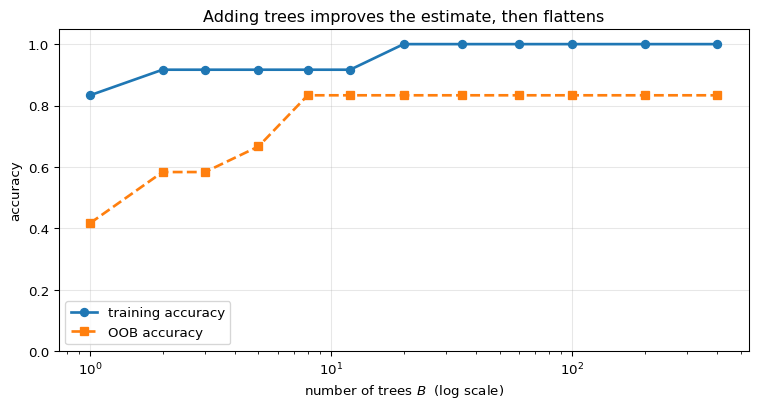


The OOB curve is noisy here because 12 rows is far too few for a stable
estimate - but it does not trend downward, which is the point.


In [14]:
Bs = [1, 2, 3, 5, 8, 12, 20, 35, 60, 100, 200, 400]
oob_curve, train_curve = [], []
for Bv in Bs:
    m = RandomForestClassifier(n_estimators=Bv, max_depth=3, max_features=2,
                               oob_score=True, bootstrap=True, random_state=0).fit(X, y_class)
    oob_curve.append(m.oob_score_)
    train_curve.append(m.score(X, y_class))

print(f"{'B':>5}  {'train acc':>10}  {'OOB acc':>9}")
print("-" * 28)
for Bv, tr_, ob in zip(Bs, train_curve, oob_curve):
    print(f"{Bv:>5}  {tr_:>10.4f}  {ob:>9.4f}")
print("-" * 28)

plt.figure(figsize=(8, 4.4))
plt.plot(Bs, train_curve, "o-", lw=2, label="training accuracy")
plt.plot(Bs, oob_curve, "s--", lw=2, label="OOB accuracy")
plt.xscale("log"); plt.xlabel("number of trees $B$  (log scale)")
plt.ylabel("accuracy"); plt.ylim(0, 1.05)
plt.title("Adding trees improves the estimate, then flattens")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("\nThe OOB curve is noisy here because 12 rows is far too few for a stable")
print("estimate - but it does not trend downward, which is the point.")

---
# 10. Summary

| Stage | Formula | Value here |
|---|---|---|
| OOB fraction | $(1 - 1/n)^n \to e^{-1}$ | $0.352$ at $n = 12$ |
| Features per split | $m = \texttt{max\_features}$ | 2 of 3 |
| Forest vote | $\hat p_1 = \frac{1}{B}\sum_b T_b(x)$ | 5 trees |
| Variance of average | $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$ | floor $= \rho\sigma^2$ |
| Importance (MDI) | $\sum_v \frac{n_v}{n}\Delta G_v$ | matches sklearn exactly |

**The one idea:** a forest trades a little bias for a large reduction in variance. Each
tree is deliberately made worse &mdash; fewer rows, fewer features &mdash; because the average
of many decorrelated mediocre trees beats one carefully grown tree.

**What is deliberately left out:** extremely randomised trees (which randomise the
threshold too), class weighting, proximity matrices, and regression forests (variance
replaces Gini, averaging replaces voting).

**What comes next:** a forest builds its trees **independently and in parallel**. The
boosting notebooks that follow build them **sequentially**, each new tree fitted to the
errors the previous ones left behind &mdash; a completely different way to use the same
split search.